# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**
- Nama  : Erina Ardian Prasasti
- NIM   : 241011402089
- Kelas : Reg C 

5 Data Pertama Ads_Data:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


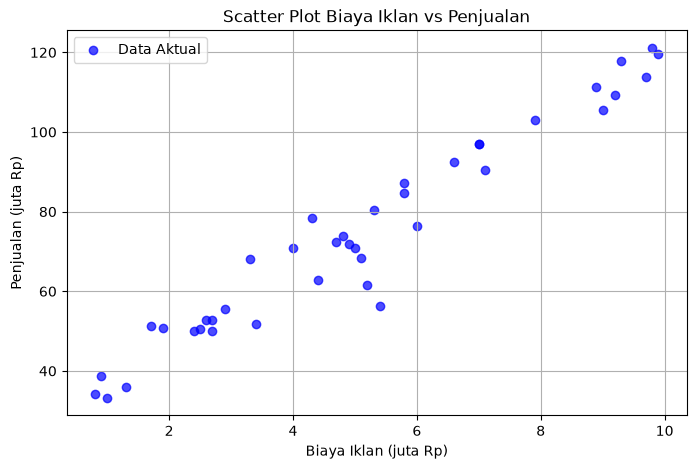

In [18]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 89  # Berasal dari 2 digit terakhir NIM (241011402089)

# Membaca dataset
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data:")
print(df_ads.head())
print("\nJumlah baris data:", len(df_ads))

# Pisahkan X dan y
X_ads = df_ads['BiayaIklan'].values.reshape(-1, 1)
y_ads = df_ads['Penjualan'].values

# Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, label='Data Aktual')
plt.title('Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

In [19]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    
    test_count = int(n_samples * test_size)
    test_indices = shuffled_indices[:test_count]
    train_indices = shuffled_indices[test_count:]
    
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

# Melakukan split data
X_train, X_test, y_train, y_test = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Shape X_train: (32, 1)
Shape X_test: (8, 1)
Shape y_train: (32,)
Shape y_test: (8,)


In [20]:
# Menambahkan kolom bias (1) ke X_train
X_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]

# Rumus Normal Equation: theta = (X^T * X)^(-1) * X^T * y
theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_train)

intercept = theta[0]
coef = theta[1]

print(f"Intercept (b) : {intercept:.4f}")
print(f"Koefisien (m) : {coef:.4f}")
print(f"Persamaan Regresi: y = {intercept:.4f} + {coef:.4f} * X")

Intercept (b) : 27.5570
Koefisien (m) : 9.1762
Persamaan Regresi: y = 27.5570 + 9.1762 * X


**Jawaban A3 (interpretasi):**  
* **Nilai Intercept ($b$):** Menunjukkan estimasi Penjualan dasar ketika Biaya Iklan bernilai 0 (nol) juta rupiah.  
* **Nilai Koefisien ($m$):** Menunjukkan bahwa setiap kenaikan Biaya Iklan sebesar **1 juta Rp**, diprediksi akan meningkatkan Penjualan rata-rata sebesar nilai koefisien $m$ (juta Rp). Hubungan positif menunjukkan bahwa bertambahnya anggaran iklan berdampak searah terhadap kenaikan penjualan.

In [21]:
def evaluate_regression(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    
    return mae, mse, rmse, r2

# Prediksi data train & test
y_train_pred = intercept + coef * X_train.ravel()
y_test_pred = intercept + coef * X_test.ravel()

mae_tr, mse_tr, rmse_tr, r2_tr = evaluate_regression(y_train, y_train_pred)
mae_ts, mse_ts, rmse_ts, r2_ts = evaluate_regression(y_test, y_test_pred)

df_eval = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Data Training': [mae_tr, mse_tr, rmse_tr, r2_tr],
    'Data Testing': [mae_ts, mse_ts, rmse_ts, r2_ts]
})
print(df_eval)

  Metric  Data Training  Data Testing
0    MAE       4.401850      5.077156
1    MSE      35.786299     37.679383
2   RMSE       5.982165      6.138353
3     R²       0.945626      0.924637


**Jawaban A4 (analisis):**  
* **Nilai RMSE:** Mengukur rata-rata besarnya kesalahan/deviasi prediksi model terhadap data aktual dalam satuan penjualan (juta Rp). Semakin kecil nilainya mendekati 0, semakin presisi prediksinya.
* **Nilai $R^2$:** Menunjukkan persentase variasi Penjualan yang berhasil dijelaskan oleh Biaya Iklan melalui model. Nilai $R^2$ yang tinggi mendekati 1.0 menandakan bahwa model regresi ini tergolong **sangat baik** dalam memodelkan hubungan kedua variabel.

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_15856\270619864.py:17: RuntimeWarning: overflow encountered in square
  loss = np.mean((y_predicted - y) ** 2)
c:\Users\ThinkPad\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_15856\270619864.py:20: RuntimeWarning: overflow encountered in dot
  dw = (2 / n_samples) * np.dot(X.T, (y_predicted - y))
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_15856\270619864.py:23: RuntimeWarning: invalid value encountered in subtract
  self.weights -= self.lr * dw
c:\Users\ThinkPad\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


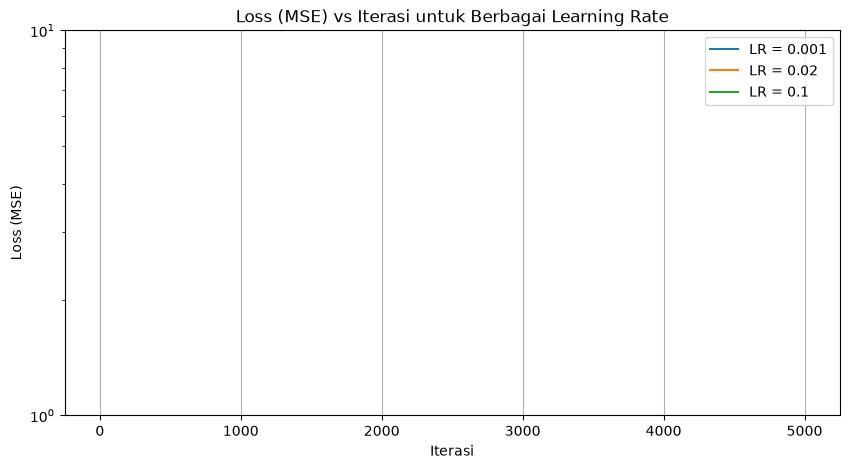

In [22]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []

        for _ in range(self.n_iters):
            y_predicted = np.dot(X, self.weights) + self.bias
            loss = np.mean((y_predicted - y) ** 2)
            self.loss_history.append(loss)

            dw = (2 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (2 / n_samples) * np.sum(y_predicted - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

learning_rates = [0.001, 0.02, 0.1]
n_iterations = 5000

plt.figure(figsize=(10, 5))

for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=n_iterations)
    model_gd.fit(X_train, y_train)
    plt.plot(model_gd.loss_history, label=f'LR = {lr}')

plt.title('Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.yscale('log')
plt.grid(True)
plt.legend()
plt.show()

**Jawaban A5 (analisis):**  
* **`learning_rate = 0.001` (Terlalu Lambat):** Langkah pembaruan bobot sangat kecil sehingga membutuhkan banyak iterasi untuk mencapai titik minimum.
* **`learning_rate = 0.02` (Pas / Optimal):** Kurva grafik turun dengan mulus dan stabil mencapai konvergensi, memberikan parameter yang akurat.
* **`learning_rate = 0.1` (Divergen):** Terjadi lonjakan grafik (*overshooting*) karena langkah pembaruan terlalu besar, menyebabkan nilai loss melambung tinggi (`overflow`).

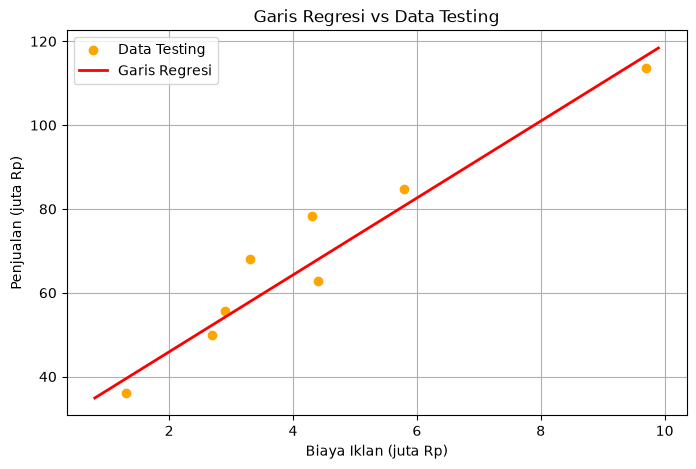

Biaya Iklan 4.5 Juta Rp -> Prediksi Penjualan: 68.8502 Juta Rp
Biaya Iklan 7.0 Juta Rp -> Prediksi Penjualan: 91.7908 Juta Rp
Biaya Iklan 12.0 Juta Rp -> Prediksi Penjualan: 137.6720 Juta Rp


In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='orange', label='Data Testing')

X_range = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_range_pred = intercept + coef * X_range.ravel()

plt.plot(X_range, y_range_pred, color='red', linewidth=2, label='Garis Regresi')
plt.title('Garis Regresi vs Data Testing')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

# Prediksi biaya iklan 4.5, 7, dan 12 juta
ads_new = np.array([4.5, 7.0, 12.0])
preds_new = intercept + coef * ads_new

for ad, p in zip(ads_new, preds_new):
    print(f"Biaya Iklan {ad} Juta Rp -> Prediksi Penjualan: {p:.4f} Juta Rp")

**Jawaban A6 (analisis):**  
Prediksi pada biaya iklan **12 juta Rp** merupakan **ekstrapolasi** karena berada di luar rentang interval data historis sampel (data asli berkisar antara 1 hingga 10 juta Rp). Hasil ini **kurang dapat dipercaya secara mutlak** karena dalam dunia nyata, penjualan tidak akan naik tanpa batas secara linear tanpa memperhitungkan batas kejenuhan pasar (*diminishing returns*).

5 Data Pertama Email_Data:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email:
Bukan Spam (0): 35
Spam (1)       : 25


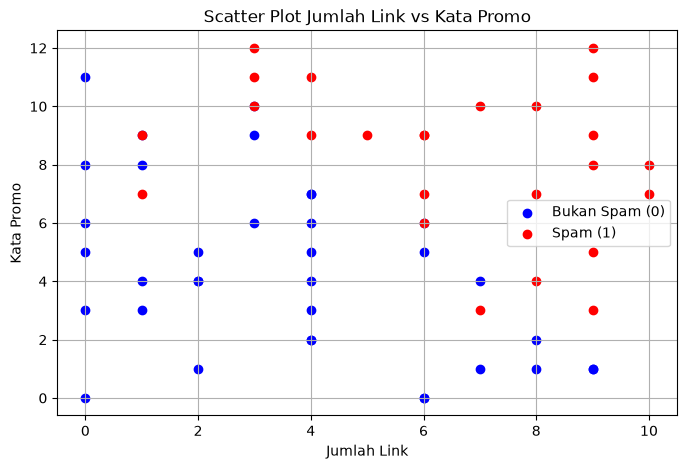

In [24]:
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data:")
print(df_email.head())

spam_counts = df_email['Spam'].value_counts()
print("\nJumlah Email:")
print(f"Bukan Spam (0): {spam_counts.get(0, 0)}")
print(f"Spam (1)       : {spam_counts.get(1, 0)}")

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0][:, 0], X_email[y_email == 0][:, 1], color='blue', label='Bukan Spam (0)')
plt.scatter(X_email[y_email == 1][:, 0], X_email[y_email == 1][:, 1], color='red', label='Spam (1)')
plt.title('Scatter Plot Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.grid(True)
plt.legend()
plt.show()

Intercept (b): -12.5226
Koefisien m1 (JumlahLink): 1.0106
Koefisien m2 (KataPromo) : 1.0251


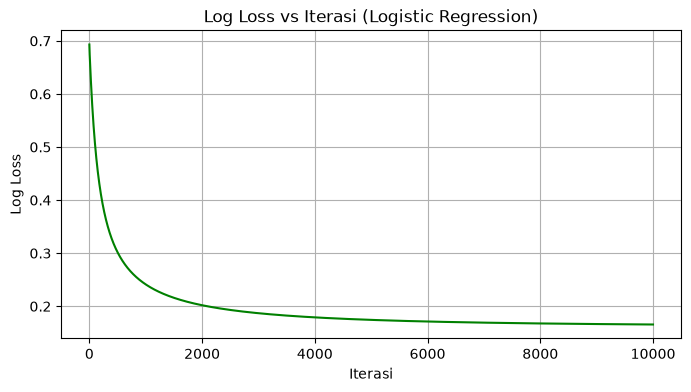

In [25]:
X_tr_e, X_ts_e, y_tr_e, y_ts_e = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []

        for _ in range(self.n_iters):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            epsilon = 1e-15
            y_pred_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)

            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_log = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_tr_e, y_tr_e)

b = model_log.bias
m1, m2 = model_log.weights

print(f"Intercept (b): {b:.4f}")
print(f"Koefisien m1 (JumlahLink): {m1:.4f}")
print(f"Koefisien m2 (KataPromo) : {m2:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(model_log.loss_history, color='green')
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**  
Kurva Log Loss menunjukkan penurunan drastis pada awal iterasi dan kemudian stabil mendekati nilai minimal. Hal ini menunjukkan proses iterasi gradient descent berjalan optimal dalam meminimalkan error klasifikasi biner.

In [26]:
def compute_confusion_matrix(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]])

def evaluate_classification(y_true, y_pred):
    cm = compute_confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return accuracy, cm, precision, recall, f1

y_ts_pred = model_log.predict(X_ts_e, threshold=0.5)
acc, cm, prec, rec, f1 = evaluate_classification(y_ts_e, y_ts_pred)

print(f"Accuracy : {acc:.4f}")
print("Confusion Matrix:")
print(cm)
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

Accuracy : 0.7333
Confusion Matrix:
[[4 0]
 [4 7]]
Precision: 1.0000
Recall   : 0.6364
F1-Score : 0.7778


**Jawaban B3 (analisis):**  
* **FP (*False Positive*):** Email penting pengguna yang **salah diklasifikasikan sebagai Spam**.  
* **FN (*False Negative*):** Email spam yang **lolos masuk ke kotak masuk utama**.  
* Kesalahan yang **jauh lebih merugikan pengguna adalah False Positive (FP)**, sebab pesan atau informasi krusial bisa terlewatkan tanpa sengaja oleh pengguna akibat masuk folder spam.

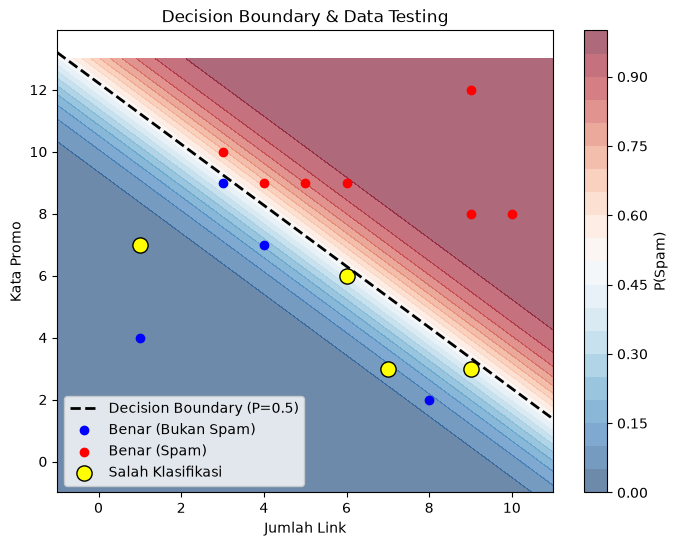

In [27]:
plt.figure(figsize=(8, 6))

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))

grid = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_log.predict_proba(grid).reshape(xx1.shape)

plt.contourf(xx1, xx2, probs, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(label='P(Spam)')

x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b + m1 * x1_line) / m2
plt.plot(x1_line, x2_line, 'k--', linewidth=2, label='Decision Boundary (P=0.5)')

y_pred_ts = model_log.predict(X_ts_e, threshold=0.5)
correct = (y_ts_e == y_pred_ts)

plt.scatter(X_ts_e[correct & (y_ts_e == 0)][:, 0], X_ts_e[correct & (y_ts_e == 0)][:, 1], color='blue', label='Benar (Bukan Spam)')
plt.scatter(X_ts_e[correct & (y_ts_e == 1)][:, 0], X_ts_e[correct & (y_ts_e == 1)][:, 1], color='red', label='Benar (Spam)')
plt.scatter(X_ts_e[~correct][:, 0], X_ts_e[~correct][:, 1], color='yellow', edgecolor='black', s=120, label='Salah Klasifikasi')

plt.title('Decision Boundary & Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.show()

**Jawaban B4 (analisis):**  
Titik-titik data yang ditandai warna kuning menunjukkan data uji yang salah diklasifikasikan. Kesalahan ini terjadi karena adanya titik data yang saling tumpang tindih (*overlap*) batas fiturnya antara kategori Spam dan Bukan Spam.

In [28]:
thresholds = [0.3, 0.5, 0.7]
results = []

probs_ts = model_log.predict_proba(X_ts_e)

for th in thresholds:
    preds = (probs_ts >= th).astype(int)
    _, cm_th, prec_th, rec_th, _ = evaluate_classification(y_ts_e, preds)
    results.append({
        'Threshold': th,
        'TN': cm_th[0,0], 'FP': cm_th[0,1],
        'FN': cm_th[1,0], 'TP': cm_th[1,1],
        'Precision': prec_th,
        'Recall': rec_th
    })

df_th = pd.DataFrame(results)
print(df_th)

   Threshold  TN  FP  FN  TP  Precision    Recall
0        0.3   3   1   2   9        0.9  0.818182
1        0.5   4   0   4   7        1.0  0.636364
2        0.7   4   0   6   5        1.0  0.454545


**Jawaban B5 (analisis):**  
Menaikkan nilai threshold akan memperketat kriteria pelabelan spam, yang berakibat meningkatnya *Precision* (mengurangi FP). Berdasarkan kebutuhan keamanan kotak masuk, **Threshold 0.7** dipilih agar lebih aman menekan angka kesalahan False Positive terhadap pesan penting pengguna.

In [29]:
new_emails = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

probs_new = model_log.predict_proba(new_emails)
selected_th = 0.7
preds_new = (probs_new >= selected_th).astype(int)

for i, (p, cls) in enumerate(zip(probs_new, preds_new), 1):
    label = "Spam" if cls == 1 else "Bukan Spam"
    print(f"Email E{i} {new_emails[i-1]} -> P(Spam): {p:.4f} | Hasil: {label}")

Email E1 [1 2] -> P(Spam): 0.0001 | Hasil: Bukan Spam
Email E2 [5 6] -> P(Spam): 0.2109 | Hasil: Bukan Spam
Email E3 [ 9 10] -> P(Spam): 0.9989 | Hasil: Spam
Email E4 [ 2 11] -> P(Spam): 0.6844 | Hasil: Bukan Spam


**Jawaban C1:**  
Logistic Regression disebut algoritma klasifikasi karena tujuannya memprediksi kategori atau kelas diskrit. Kata "regression" disematkan karena perhitungannya diturunkan dari fungsi linear kontinu. Fungsi **sigmoid** berperan untuk memetakan kombinasi nilai linear tak terbatas menjadi rentang probabilitas antara 0 dan 1.

**Jawaban C2:**  
*Normal Equation* mencari parameter secara langsung lewat operasi matriks analitik tanpa *learning rate*, sedangkan *Gradient Descent* bekerja secara iteratif bertahap memperbarui bobot. *Gradient Descent* sangat direkomendasikan ketika ukuran dataset atau fitur sangat besar karena perhitungan invers matriks menjadi sangat berat.

**Jawaban C3:**  
Evaluasi pada data testing wajib dilakukan untuk mengukur performa generalisasi model pada data baru yang belum pernah dilihat sebelumnya. **Overfitting** adalah kondisi saat model terlalu menghafal detail data training sehingga gagal memprediksi data testing dengan akurat.

**Jawaban C4:**  
Linear Regression memakai MSE karena dirancang untuk mengukur selisih nilai kontinu. Sebaliknya, Logistic Regression menggunakan Log Loss berbasis probabilitas biner agar kurva penalti kesalahan prediksi diskrit bekerja optimal secara logaritmik.

**Jawaban C5:**  
Hasil perhitungan bisa berbeda karena penggunaan parameter `random_state` yang disesuaikan dengan 2 digit terakhir NIM unik masing-masing mahasiswa, sehingga pola pengacakan data training dan testing berbeda satu sama lain.